# DW analysis insight graphs

This notebook creates display-only Seaborn/Matplotlib charts from `query_results.txt`. It does not save, embed, or modify any graphs.

In [37]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 120


In [38]:
# Read the six result tables already recorded by DW_query.sql.
import re

result_file = next(path for path in (Path('query_results.txt'), Path('../query_results.txt')) if path.exists())

def read_mysql_tables(path):
    pattern = re.compile(
        r'^\+[-+]+\+\r?\n'
        r'(?P<header>\|.*\|)\r?\n'
        r'^\+[-+]+\+\r?\n'
        r'(?P<rows>(?:\|.*\|\r?\n)+)'
        r'^\+[-+]+\+$',
        flags=re.MULTILINE,
    )

    def split_row(row):
        return [value.strip() for value in row.strip().strip('|').split('|')]

    tables = []
    for match in pattern.finditer(path.read_text(encoding='utf-8')):
        header = split_row(match.group('header'))
        rows = [split_row(row) for row in match.group('rows').splitlines() if row.startswith('|')]
        tables.append(pd.DataFrame(rows, columns=header))
    if len(tables) != 6:
        raise ValueError(f'Expected 6 result tables, found {len(tables)}.')
    return tables

monthly, weekday, genre, member_activity, tier, seasonal = read_mysql_tables(result_file)

for frame in (monthly, weekday, genre, member_activity, tier, seasonal):
    for column in frame.columns:
        try:
            frame[column] = pd.to_numeric(frame[column])
        except (TypeError, ValueError):
            pass

month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']
monthly['MonthNumber'] = monthly['MonthName'].map({name: index + 1 for index, name in enumerate(month_order)})
monthly['Period'] = pd.to_datetime(dict(year=monthly['Year'], month=monthly['MonthNumber'], day=1))
weekday['DayOfWeek'] = pd.Categorical(weekday['DayOfWeek'],
                                      categories=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'],
                                      ordered=True)
seasonal['MonthName'] = pd.Categorical(seasonal['MonthName'], categories=month_order, ordered=True)

# Results supplied for DW_query.sql Queries 7 and 8.
staff_workload = pd.DataFrame([
    ['Circulation', 'Part-time', 2243, 8.84, 8.29],
    ['Circulation', 'Full-time', 1963, 8.89, 8.78],
    ['Inventory', 'Full-time', 1692, 8.57, 8.10],
    ['Digital Services', 'Part-time', 1484, 9.01, 8.89],
    ['Inventory', 'Part-time', 1463, 8.84, 8.75],
    ['Reference', 'Full-time', 1283, 8.73, 8.26],
    ['Reference', 'Part-time', 705, 8.71, 8.94],
    ['Membership', 'Part-time', 515, 7.77, 7.77],
    ['Membership', 'Full-time', 507, 8.69, 7.50],
    ['Digital Services', 'Full-time', 470, 9.18, 8.72],
], columns=['Department', 'EmploymentType', 'CompletedLoans', 'AvgLoanDurationDays', 'LateReturnRatePct'])

return_bands = pd.DataFrame([
    ['On time or early', 11298, 91.53, 7.37],
    ['1-3 days late', 189, 1.53, 15.86],
    ['4-7 days late', 205, 1.66, 19.54],
    ['8+ days late', 651, 5.27, 28.50],
], columns=['ReturnTimingBand', 'LoanCount', 'SharePct', 'AvgLoanDurationDays'])


## 1. Monthly loan volume and average duration

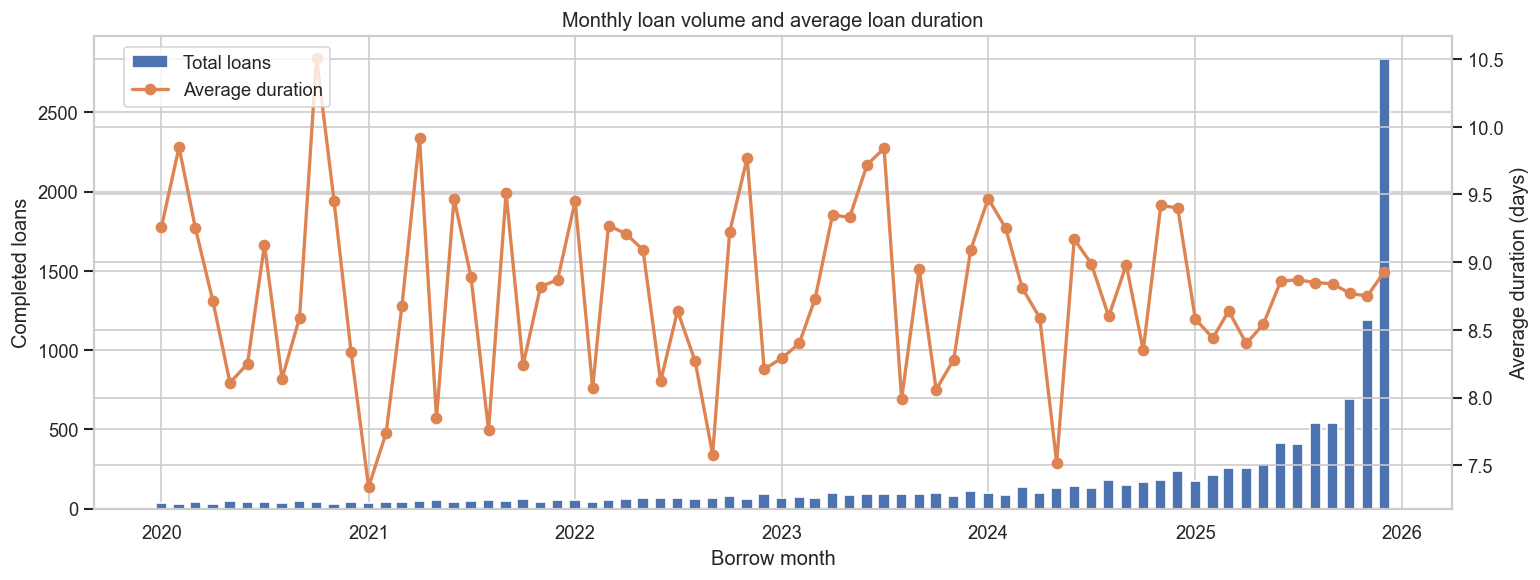

In [39]:
fig, ax_loans = plt.subplots(figsize=(13, 5))
ax_loans.bar(monthly['Period'], monthly['TotalLoans'], width=20, color='#4C72B0', label='Total loans')
ax_loans.set_xlabel('Borrow month')
ax_loans.set_ylabel('Completed loans')
ax_duration = ax_loans.twinx()
ax_duration.plot(monthly['Period'], monthly['AvgDurationDays'], color='#DD8452', marker='o', linewidth=2, label='Average duration')
ax_duration.set_ylabel('Average duration (days)')
ax_loans.set_title('Monthly loan volume and average loan duration')
fig.legend(loc='upper left', bbox_to_anchor=(0.08, 0.92))
fig.tight_layout()
plt.show()


## 2. Borrowing pattern by day of week

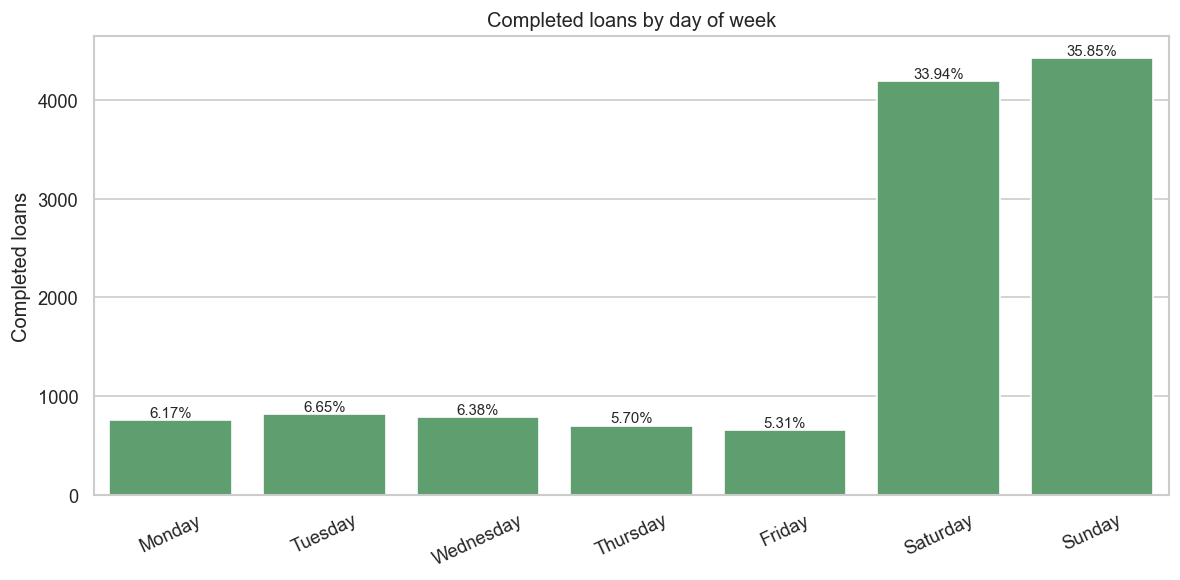

In [40]:
day_plot = weekday.sort_values('DayOfWeek')
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=day_plot, x='DayOfWeek', y='TotalLoans', color='#55A868', ax=ax)
for bar, percentage in zip(ax.patches, day_plot['PctOfAllLoans']):
    ax.annotate(f'{percentage:.2f}%', (bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha='center', va='bottom', fontsize=9)
ax.set(title='Completed loans by day of week', xlabel='', ylabel='Completed loans')
ax.tick_params(axis='x', rotation=25)
fig.tight_layout()
plt.show()


## 3. Genre popularity and borrowing intensity

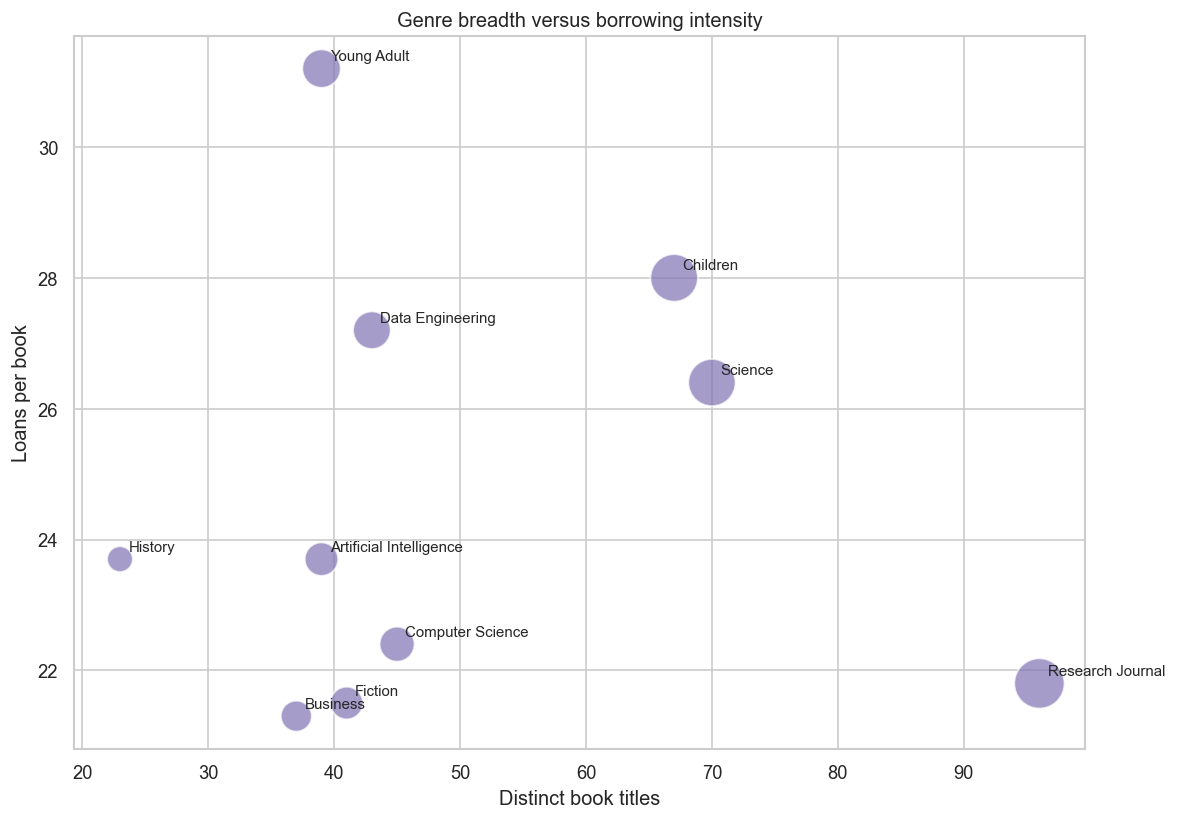

In [41]:
fig, ax = plt.subplots(figsize=(10, 7))
sizes = genre['TotalLoans'] / genre['TotalLoans'].max() * 900
ax.scatter(genre['DistinctBooks'], genre['LoansPerBook'], s=sizes, alpha=0.7, color='#8172B3', edgecolor='white')
for _, row in genre.iterrows():
    ax.annotate(row['Genre'], (row['DistinctBooks'], row['LoansPerBook']), xytext=(5, 5), textcoords='offset points', fontsize=9)
ax.set(title='Genre breadth versus borrowing intensity', xlabel='Distinct book titles', ylabel='Loans per book')
fig.tight_layout()
plt.show()


## 4. Members with the highest and lowest borrowing activity

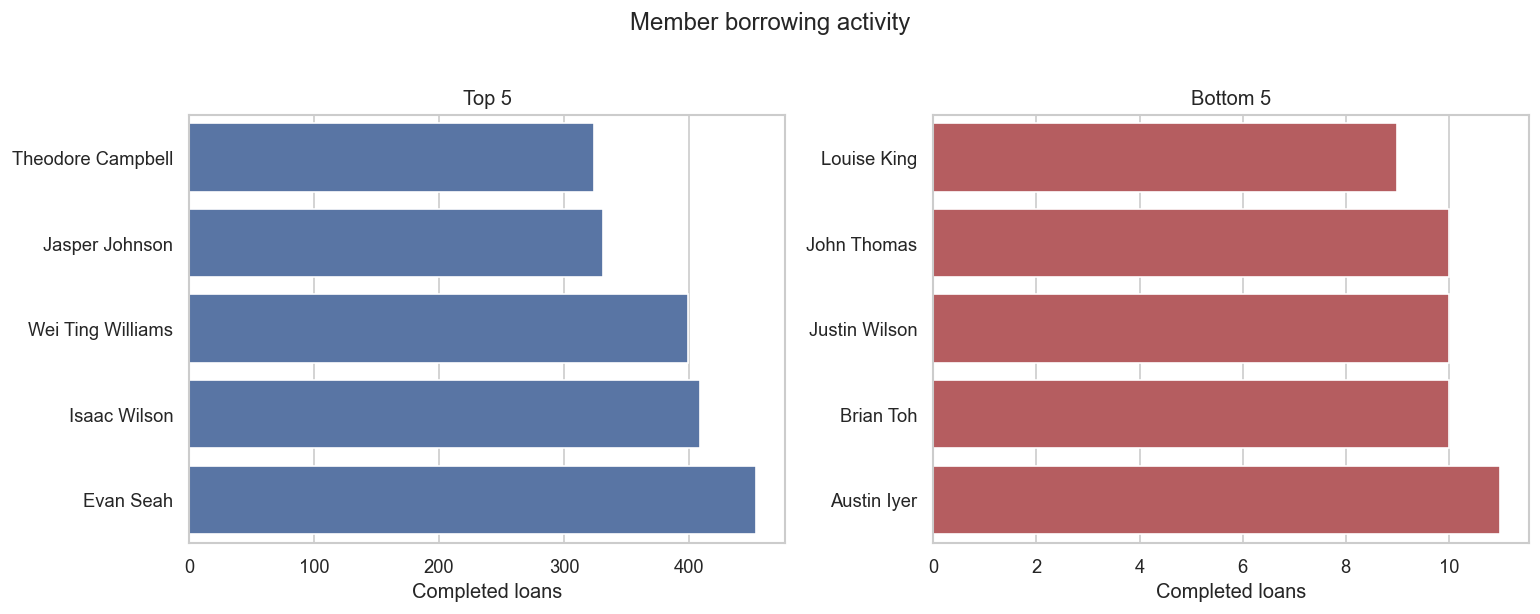

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=False)
for ax, group, colour in zip(axes, ['Top 5', 'Bottom 5'], ['#4C72B0', '#C44E52']):
    subset = member_activity[member_activity['Grp'] == group].sort_values('TotalLoans')
    sns.barplot(data=subset, x='TotalLoans', y='Name', color=colour, ax=ax)
    ax.set(title=group, xlabel='Completed loans', ylabel='')
fig.suptitle('Member borrowing activity', y=1.02)
fig.tight_layout()
plt.show()


## 5. Loan duration and late-return rate by membership tier

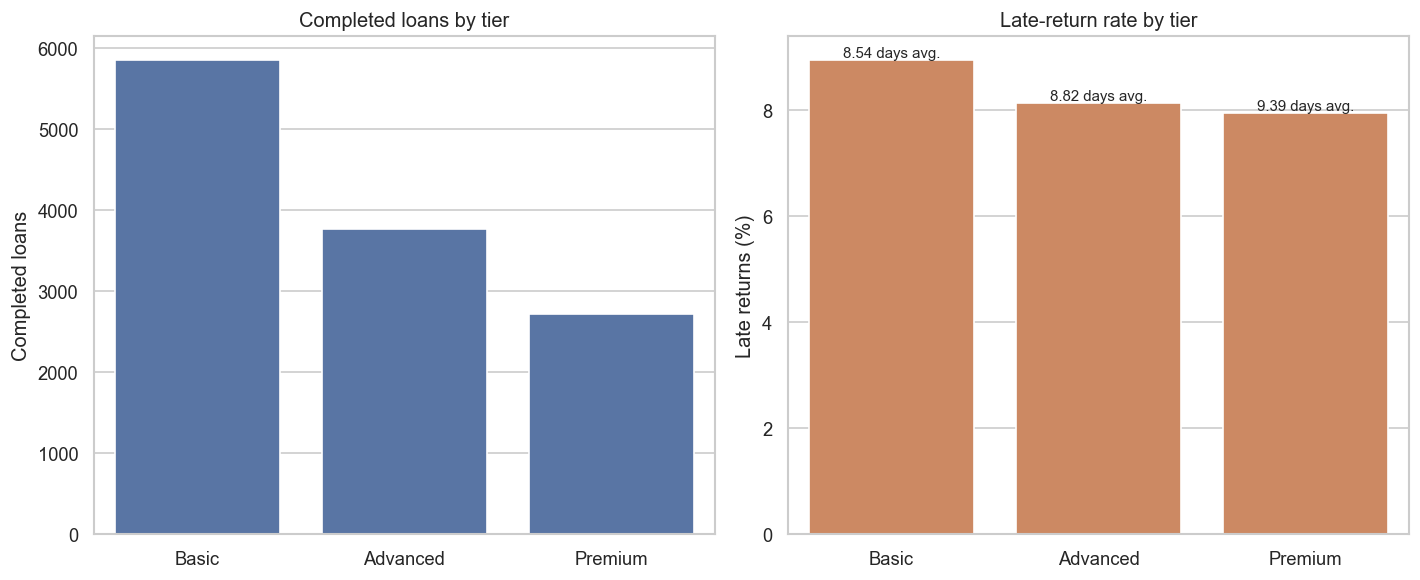

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(data=tier, x='TierName', y='TotalLoans', color='#4C72B0', ax=axes[0])
axes[0].set(title='Completed loans by tier', xlabel='', ylabel='Completed loans')
sns.barplot(data=tier, x='TierName', y='LatePct', color='#DD8452', ax=axes[1])
for bar, duration in zip(axes[1].patches, tier['AvgDurationDays']):
    axes[1].annotate(f'{duration:.2f} days avg.', (bar.get_x() + bar.get_width()/2, bar.get_height()),
                     ha='center', va='bottom', fontsize=9)
axes[1].set(title='Late-return rate by tier', xlabel='', ylabel='Late returns (%)')
fig.tight_layout()
plt.show()


## 6. Monthly demand for Children and Young Adult titles

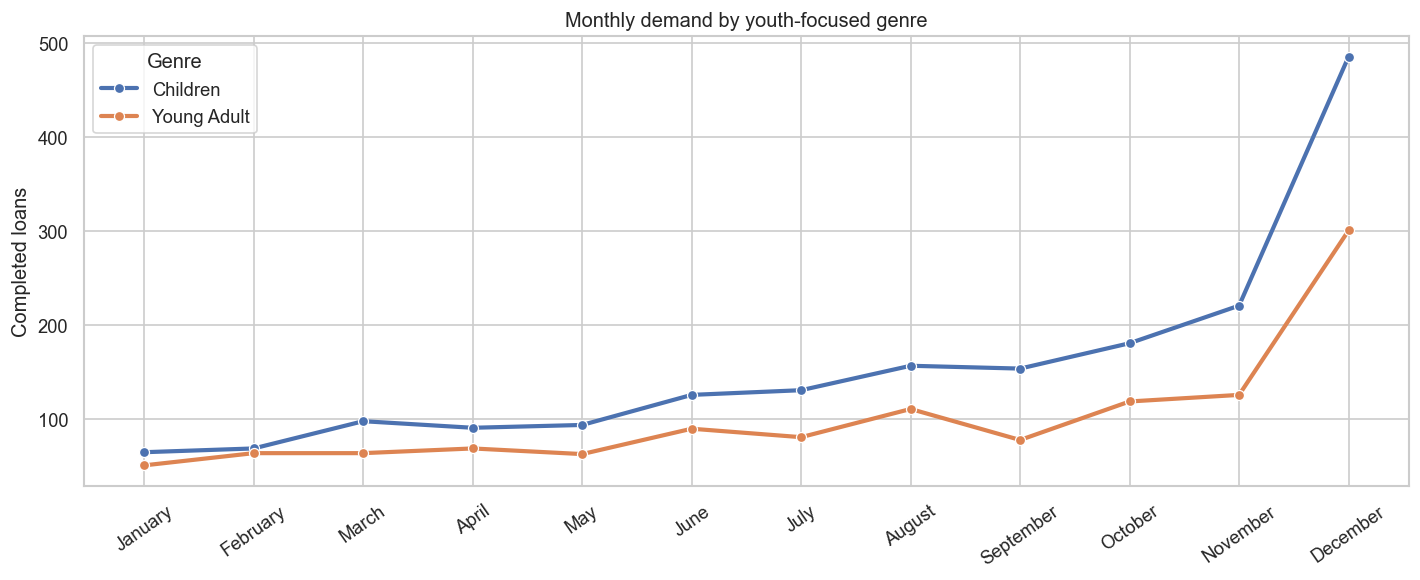

In [44]:
season_plot = seasonal.sort_values(['Genre', 'Month'])
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=season_plot, x='MonthName', y='TotalLoans', hue='Genre', marker='o', linewidth=2.5, ax=ax)
ax.set(title='Monthly demand by youth-focused genre', xlabel='', ylabel='Completed loans')
ax.tick_params(axis='x', rotation=35)
fig.tight_layout()
plt.show()


## 7. Staff workload by department and employment type

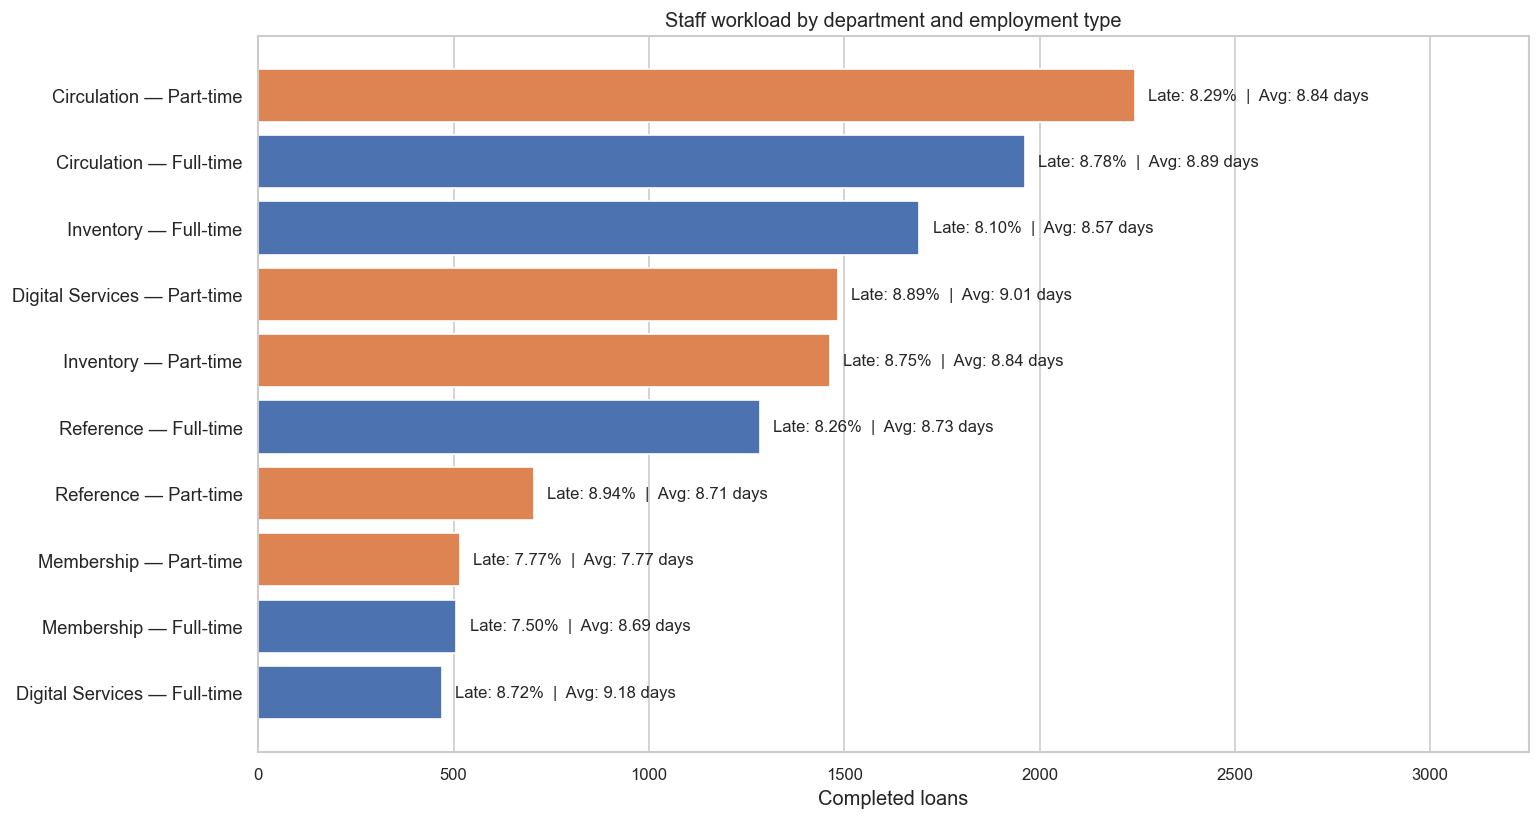

In [45]:
staff_plot = staff_workload.sort_values('CompletedLoans').copy()
type_colours = {'Full-time': '#4C72B0', 'Part-time': '#DD8452'}
staff_plot['Label'] = staff_plot['Department'] + ' — ' + staff_plot['EmploymentType']
fig, ax = plt.subplots(figsize=(13, 7))
bars = ax.barh(staff_plot['Label'],
               staff_plot['CompletedLoans'],
               color=staff_plot['EmploymentType'].map(type_colours))
for bar, (_, row) in zip(bars, staff_plot.iterrows()):
    ax.annotate(f"Late: {row['LateReturnRatePct']:.2f}%  |  Avg: {row['AvgLoanDurationDays']:.2f} days",
                (bar.get_width(), bar.get_y() + bar.get_height()/2),
                xytext=(8, 0), textcoords='offset points', va='center', fontsize=10)
ax.set(title='Staff workload by department and employment type',
       xlabel='Completed loans', ylabel='')
ax.set_xlim(0, staff_plot['CompletedLoans'].max() * 1.45)
ax.grid(axis='y', visible=False)
ax.tick_params(axis='y', labelsize=11)
ax.tick_params(axis='x', labelsize=10)
fig.tight_layout()
plt.show()


## 8. Severity bands for late returns

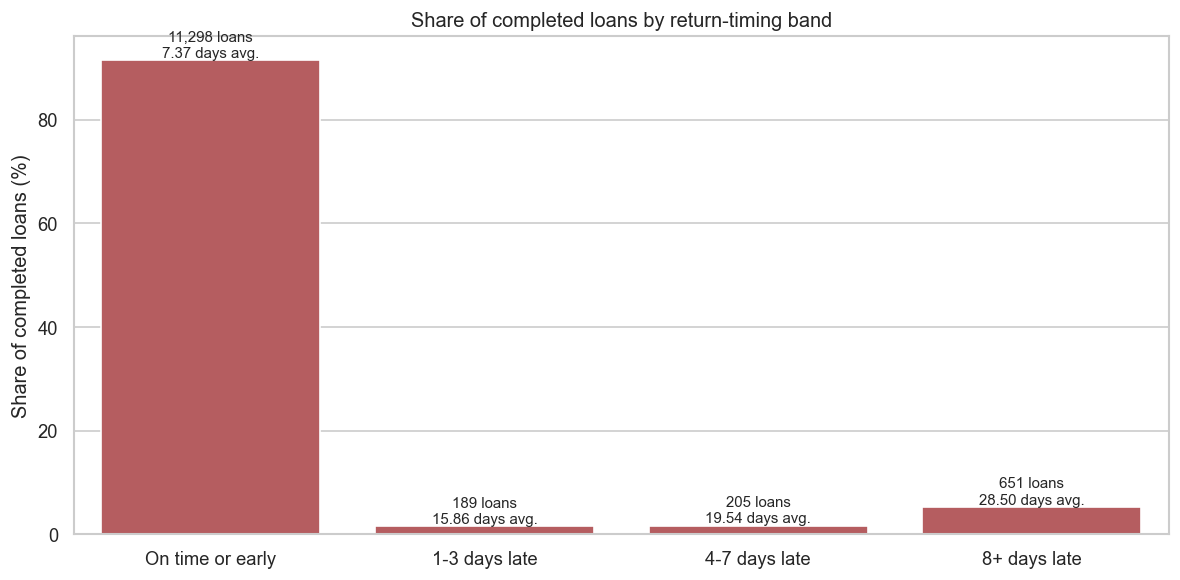

In [46]:
band_order = ['On time or early', '1-3 days late', '4-7 days late', '8+ days late']
return_bands['ReturnTimingBand'] = pd.Categorical(return_bands['ReturnTimingBand'],
                                               categories=band_order, ordered=True)
band_plot = return_bands.sort_values('ReturnTimingBand')
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=band_plot, x='ReturnTimingBand', y='SharePct', color='#C44E52', ax=ax)
for bar, (_, row) in zip(ax.patches, band_plot.iterrows()):
    ax.annotate(f"{row['LoanCount']:,} loans\n{row['AvgLoanDurationDays']:.2f} days avg.",
                (bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha='center', va='bottom', fontsize=9)
ax.set(title='Share of completed loans by return-timing band',
       xlabel='', ylabel='Share of completed loans (%)')
fig.tight_layout()
plt.show()
